# 2026 지옥캠프 — 실험 007 — Strong 기반 EfficientNet-B0 앙상블

SEED 하나로 데이터 분할과 모델 시드 4개를 설정합니다. SEED=1이면 모델 시드는 1·2·3·4입니다.
네 모델 모두 strong 기반 증강을 사용합니다. SEED·SEED+1은 strong, SEED+2는 strong+가림, SEED+3은 strong+원근 변형입니다.
실행 위치는 프로젝트 루트이며 학습 코드의 저장본을 실험 폴더에 복사합니다.
모든 테스트에서 기존 조건부 temperature 규칙과 전체 T=0.5 규칙을 함께 평가하고 CSV로 생성합니다.
- 작성 환경: Google Colab (CPU만으로도 동작) / 로컬 Python 3.10+, PyTorch 2.x
- GPU가 있으면 자동으로 사용하지만 **필수는 아닙니다**

## 대회 규칙 요약 (필독)

| 항목 | 내용 |
|---|---|
| 과제 | 사진 → **6공학관(0) / IT관(1)** 이진 분류 |
| 참가 | 개인전 |
| 기간 | 2026-11-07(토) ~ 11-08(일) |
| 지표 | **Log Loss** (낮을수록 우수, 확률을 제출해야 함) |
| 모델 제약 | **총 파라미터 20M 이하** (앙상블·사전학습 백본 합산) |
| 런타임 | **Colab CPU 기준** 테스트 500장 10분 이내 · 실행 중 다운로드 금지 (사전학습 가중치는 최종 파일에 포함) |
| 금지 | 외부 이미지 사용, 테스트 이미지를 학습에 사용(pseudo-labeling 포함) |
| 제출 | 예측 CSV **10분에 1회 · 하루 최대 50회** (공개 리더보드) + 마감 시 최종 파일 1개 (형식 자유) |
| 순위 | 테스트 500장 중 Public 250장 = 공개 리더보드, **Private 250장 = 최종 순위** (어느 장이 Private 인지는 비공개) |


## 실행 전 사전 준비

### 모듈
Colab은 필요한 모듈이 모두 설치되어 있습니다. 로컬이라면:
```shell
# 본인 환경(CPU/CUDA)에 맞는 PyTorch 설치: https://pytorch.org/get-started/locally/
pip3 install torch torchvision
pip3 install -U scikit-learn matplotlib
```

### 데이터 파일
운영진이 배포한 데이터를 노트북과 같은 폴더에 압축해제해 주세요 (Colab 은 `/content`).
```
📁root
 ├─📁train
 │  ├─📁6e      ← 6공학관 (label 0)
 │  └─📁it      ← IT관   (label 1)
 ├─📁test       ← 테스트 500장 (Public 250 + Private 250)
 └─📜baseline.ipynb
```


## 모듈 불러오기 & 시드 고정

재현성을 위해 모든 난수 시드를 고정합니다. 시드가 고정되어 있어야 "내가 바꾼 것 때문에 점수가 오른 것인지, 운이 좋았던 것인지"를 구분할 수 있습니다.

In [ ]:
import csv
import os
import random
import shutil
import subprocess
import time

import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Dataset, Subset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from PIL import Image


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)


SEED = 42
seed_everything(SEED)

In [2]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('사용 장치:', device)
if torch.cuda.is_available():
    print(torch.cuda.get_device_name())

사용 장치: cuda:0
NVIDIA GeForce RTX 3080


## 하이퍼 파라미터

In [3]:
params = {
    'epoch': 50,
    'early_stopping': True,
    'min_epochs': 5,       # 각 학습률의 최소 학습 epoch, 이후부터 미개선 횟수 집계
    'patience': 5,
    'batch_size': 32,
    'learning_rates': (1e-3, 3e-4, 1e-4),
    'valid_ratio': 0.15,   # 학습 2,906장 중 검증으로 떼어둘 비율
    'workers': 0,          # Windows 노트북의 워커 프로세스 멈춤 방지; 모든 실험에 공통 적용
    'num_show_img': 5,     # 데이터 확인용 표시 개수 (학습과 무관)
}

In [4]:
# label 0 = 6공학관(6e), label 1 = IT관(it)
class_names = {0: '6e', 1: 'it'}

RUN_SEEDS = tuple(range(SEED, SEED + 4))
AUGMENTATION_BY_SEED = dict(zip(RUN_SEEDS, ("strong", "strong", "erasing", "perspective")))
print("분할 시드:", SEED, "/ 모델 시드:", RUN_SEEDS)


분할 시드: 1 / 모델 시드: (1, 2, 3, 4)


## 결과 폴더와 제출 이름

결과는 `실험결과/007_Strong기반앙상블/seed_{SEED}/`에 저장합니다.
SEED만 바꾸면 분할, 모델 시드 4개, 결과 경로, 제출 CSV 이름이 함께 바뀝니다.
최종 앙상블 CSV는 `submission_{SEED}_T0.3.csv`, `submission_{SEED}_T0.5.csv`, `submission_{SEED}_T0.3_TTA.csv` 세 개입니다.
TTA는 각 모델에서 원본·좌우 반전 확률을 평균한 뒤, 기존 결합 방식과 조건부 T0.3을 적용합니다.
T0.3은 전원 일치 T=0.3·불일치 T=0.7인 기존 규칙의 이름입니다. T0.5는 같은 결합 확률에 모두 T=0.5를 적용합니다.
같은 SEED로 재실행하면 같은 폴더의 결과 파일을 덮어씁니다.

학습 시작 시 저장된 baseline_test.ipynb와 model.py를 해당 seed 폴더의 코드/에 복사합니다. 실행 전에 노트북을 저장하세요.


In [5]:
from pathlib import Path

BASE_DIR = Path.cwd().resolve()
assert (BASE_DIR / "train").is_dir(), f"작업 폴더에 train이 없습니다: {BASE_DIR}"

RESULT_DIR = BASE_DIR / "실험결과" / "007_Strong기반앙상블" / f"seed_{SEED}"
GRAPH_DIR = RESULT_DIR / "graphs"
CHECKPOINT_DIR = RESULT_DIR / "checkpoints"
EPOCH_DIR = RESULT_DIR / "epochs"
CODE_DIR = RESULT_DIR / "코드"

GRAPH_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
EPOCH_DIR.mkdir(parents=True, exist_ok=True)
CODE_DIR.mkdir(parents=True, exist_ok=True)

print("그래프 저장 폴더:", GRAPH_DIR)
print("학습 가중치 저장 폴더:", CHECKPOINT_DIR)

print("epoch CSV 저장 폴더:", EPOCH_DIR)


그래프 저장 폴더: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\graphs
학습 가중치 저장 폴더: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints
epoch CSV 저장 폴더: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\epochs


## 모델 정의 (`model.py` 생성)

EfficientNet-B0는 이진 분류용 logit 1개를 출력합니다.
학습 시 `pretrained=True`로 ImageNet 사전학습 가중치를 불러와 전체 파라미터를 학습합니다.
Torchvision은 최초 학습 때 가중치를 다운로드하고 이후 캐시를 재사용합니다.
`pretrained=False`는 구조만 생성하므로 제출 패키지에서 다운로드 없이 최종 가중치를 불러올 수 있습니다.


In [6]:
%%writefile model.py
import torch
import torch.nn as nn
from torchvision import models
from torchvision import transforms
from torchvision.transforms import functional as F

IMG_SIZE = 256
NORM_MEAN = (0.485, 0.456, 0.406)
NORM_STD = (0.229, 0.224, 0.225)
PAD_FILL = tuple(round(value * 255) for value in NORM_MEAN)
CONSENSUS_TEMPERATURE = 0.3
DISAGREEMENT_TEMPERATURE = 0.7
TEMPERATURE_RULES = ("T0.3", "T0.5")


def resize_pad(image):
	width, height = image.size
	scale = IMG_SIZE / max(width, height)
	new_width = max(1, round(width * scale))
	new_height = max(1, round(height * scale))
	image = F.resize(image, [new_height, new_width], antialias=True)
	left = (IMG_SIZE - new_width) // 2
	top = (IMG_SIZE - new_height) // 2
	return F.pad(image, [left, top, IMG_SIZE - new_width - left, IMG_SIZE - new_height - top], fill=PAD_FILL)


class RandomAreaCrop:
	def __init__(self, scale):
		self.scale = scale

	def __call__(self, image):
		top, left, height, width = transforms.RandomResizedCrop.get_params(image, scale=self.scale, ratio=(0.75, 4 / 3))
		return F.crop(image, top, left, height, width)


def build_valid_transform():
	return transforms.Compose([
		transforms.Lambda(resize_pad),
		transforms.ToTensor(),
		transforms.Normalize(NORM_MEAN, NORM_STD),
	])


def combine_probabilities(member_probs, temperature_rule="T0.3"):
	assert (member_probs.ndim == 2) and (member_probs.shape[1] == 4)
	votes = member_probs >= 0.5
	unanimous = (votes == votes[:, :1]).all(dim=1, keepdim=True)
	middle_mean = member_probs.sort(dim=1).values[:, 1:3].mean(dim=1, keepdim=True)
	probs = torch.where(unanimous, member_probs.mean(dim=1, keepdim=True), middle_mean)
	if temperature_rule == "T0.3":
		temperatures = torch.where(unanimous, CONSENSUS_TEMPERATURE, DISAGREEMENT_TEMPERATURE)
	elif temperature_rule == "T0.5":
		temperatures = 0.5
	else:
		raise ValueError(f"알 수 없는 temperature 규칙: {temperature_rule}")
	return torch.sigmoid(torch.logit(probs) / temperatures)


def build_model(pretrained=False):
	weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
	net = models.efficientnet_b0(weights=weights)
	net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, 1)
	return net


class EfficientNetEnsemble(nn.Module):
	def __init__(self, state_dicts):
		super().__init__()
		assert len(state_dicts) == 4, "앙상블 가중치 4개가 필요합니다."
		self.models = nn.ModuleList()
		for state_dict in state_dicts:
			model = build_model()
			model.load_state_dict(state_dict)
			self.models.append(model)

	def member_probabilities(self, inputs):
		return torch.cat([torch.sigmoid(model(inputs)) for model in self.models], dim=1)

	def forward(self, inputs, temperature_rule="T0.3"):
		return combine_probabilities(self.member_probabilities(inputs), temperature_rule)


Overwriting model.py


In [7]:
import importlib
import model as model_module

importlib.reload(model_module)


<module 'model' from 'c:\\Users\\행조\\OneDrive\\문서\\ChatGPT\\aid mini 대회\\model.py'>

### 파라미터 제한

각 실행에서 모델을 새로 만들고 총 파라미터 수가 20,000,000 이하인지 확인합니다.


In [8]:
PARAM_LIMIT = 20_000_000
print(f"EfficientNet-B0 {len(RUN_SEEDS)}개 / Log Loss 기준 / 의견 일치 여부에 따른 앙상블")


EfficientNet-B0 4개 / Log Loss 기준 / 의견 일치 여부에 따른 앙상블


## Strong 기반 증강

네 모델 모두 크롭 면적 50–100%, 밝기·대비 ±40%, 채도 ±30%, 좌우 반전 확률 0.5를 사용합니다.
SEED·SEED+1은 strong, SEED+2는 strong+가림, SEED+3은 strong+원근 변형입니다.
가림은 확률 10%, 면적 2–10%이며, 원근 변형은 확률 30%, distortion_scale=0.15입니다.
검증·추론은 원본 비율을 유지해 긴 변을 256으로 맞춘 뒤 중앙 패딩합니다.
학습도 영역을 자른 뒤 같은 비율 보존·패딩 과정을 거칩니다.


In [9]:
data_path = BASE_DIR / "train"
IMG_SIZE = model_module.IMG_SIZE
NORM_MEAN = model_module.NORM_MEAN
NORM_STD = model_module.NORM_STD

AUGMENTATION_SETTINGS = {
	"strong": {"scale_min": 0.5, "brightness": 0.4, "contrast": 0.4, "saturation": 0.3, "erase_p": 0.0, "perspective_p": 0.0, "distortion_scale": 0.0},
	"erasing": {"scale_min": 0.5, "brightness": 0.4, "contrast": 0.4, "saturation": 0.3, "erase_p": 0.1, "perspective_p": 0.0, "distortion_scale": 0.0},
	"perspective": {"scale_min": 0.5, "brightness": 0.4, "contrast": 0.4, "saturation": 0.3, "erase_p": 0.0, "perspective_p": 0.3, "distortion_scale": 0.15},
}
train_transforms = {}
for name, settings in AUGMENTATION_SETTINGS.items():
	operations = [
		model_module.RandomAreaCrop(scale=(settings["scale_min"], 1.0)),
		transforms.RandomHorizontalFlip(p=0.5),
		transforms.ColorJitter(brightness=settings["brightness"], contrast=settings["contrast"], saturation=settings["saturation"]),
	]
	if settings["perspective_p"] > 0:
		operations.append(transforms.RandomPerspective(distortion_scale=settings["distortion_scale"], p=settings["perspective_p"], fill=model_module.PAD_FILL))
	operations.extend([
		transforms.Lambda(model_module.resize_pad),
		transforms.ToTensor(),
		transforms.Normalize(NORM_MEAN, NORM_STD),
	])
	if settings["erase_p"] > 0:
		operations.append(transforms.RandomErasing(p=settings["erase_p"], scale=(0.02, 0.1), value=0))
	train_transforms[name] = transforms.Compose(operations)

train_transform = train_transforms["strong"]
valid_transform = model_module.build_valid_transform()
full_train = datasets.ImageFolder(data_path, train_transform)
full_valid = datasets.ImageFolder(data_path, valid_transform)
print("클래스 → 라벨 매핑:", full_train.class_to_idx)
print("전체 이미지 수:", len(full_train))
print("입력 크기:", IMG_SIZE, "비율 보존 및 중앙 패딩")


클래스 → 라벨 매핑: {'6e': 0, 'it': 1}
전체 이미지 수: 2906
입력 크기: 256 비율 보존 및 중앙 패딩


### Train / Valid 분할

분할 시드는 SEED, 검증 비율은 15%입니다. 같은 실험 내 네 모델은 동일한 학습·검증 인덱스를 사용합니다. 새 분할에서는 네 모델을 처음부터 학습합니다.


In [10]:
labels = [y for _, y in full_train.samples]
train_idx, valid_idx = train_test_split(
    list(range(len(full_train))),
    test_size=params['valid_ratio'],
    stratify=labels,
    random_state=SEED,
)

data_sets = {
    'train': Subset(full_train, train_idx),
    'valid': Subset(full_valid, valid_idx),
}
print(f"train: {len(data_sets['train'])}장 / valid: {len(data_sets['valid'])}장")

train: 2470장 / valid: 436장


In [11]:
g = torch.Generator()
g.manual_seed(SEED)

dataloaders = {
    'train': DataLoader(data_sets['train'], batch_size=params['batch_size'],
                        shuffle=True, num_workers=params['workers'], generator=g),
    'valid': DataLoader(data_sets['valid'], batch_size=params['batch_size'],
                        shuffle=False, num_workers=params['workers']),
}
print('배치 수 — train: %d / valid: %d' % (len(dataloaders['train']), len(dataloaders['valid'])))

배치 수 — train: 78 / valid: 14


### 데이터 확인

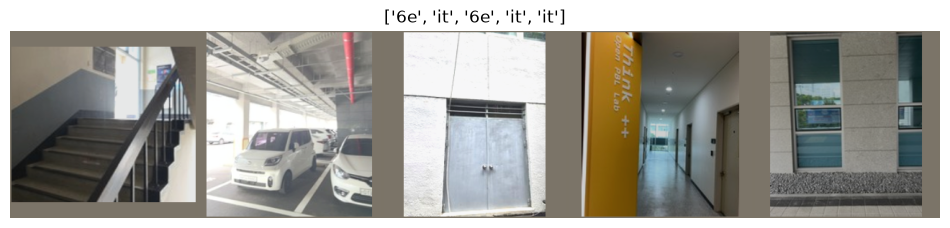

In [12]:
def img_show(tensor, title=None):
    arr = tensor.numpy().transpose((1, 2, 0))
    arr = arr * np.array(NORM_STD) + np.array(NORM_MEAN)  # 정규화 되돌리기 (표시용)
    arr = np.clip(arr, 0, 1)
    plt.figure(figsize=(12, 4))
    plt.imshow(arr)
    plt.axis('off')
    if title is not None:
        plt.title(title)
    plt.show()


inputs, classes = next(iter(dataloaders['train']))
out = torchvision.utils.make_grid(inputs[:params['num_show_img']])
img_show(out, title=[class_names[int(c)] for c in classes[:params['num_show_img']]])

## 학습 — EfficientNet-B0 × 4회

모델 시드는 SEED부터 연속된 4개이며, 데이터 분할 시드는 SEED입니다. 각 실행은 ImageNet 사전학습 가중치에서 새로 시작합니다.
가중치 선택과 학습률 전환은 검증 Log Loss를 기준으로 합니다. Log Loss 동률의 가중치는 ACC가 높은 것을 선택합니다.
학습률은 0.001 → 0.0003 → 0.0001 순서입니다.
각 단계는 최소 5 epoch를 학습하고, 그 이후부터 해당 단계의 최저 검증 Log Loss를 5회 연속 갱신하지 못하면 다음 단계로 넘어갑니다.
단계가 바뀌면 단계별 최저 손실과 대기 횟수를 초기화합니다. 마지막 단계에서 같은 조건을 만족하면 종료합니다.
전체 최대 50 epoch 상한을 적용합니다. 계속 정체되면 10·20 epoch 종료 후 전환하고 30 epoch에서 종료합니다.

모든 epoch의 학습률·단계 번호·단계 내 epoch·학습/검증 손실과 정확도를 CSV에 즉시 저장합니다.
진행 막대는 표시하지 않습니다.

같은 분할과 모델 시드를 사용한 실험 006과 비교합니다. SEED+1의 strong 설정은 006과 동일합니다.


In [13]:
def run_epoch(model, loader, criterion, optimizer=None):
    """optimizer가 주어지면 학습, 아니면 평가. (평균 loss, 정확도)를 반환."""
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss, total_correct, total_n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for inputs, targets in loader:
            inputs = inputs.to(device)
            targets = targets.float().unsqueeze(1).to(device)  # (B,) -> (B,1)

            logits = model(inputs)
            loss = criterion(logits, targets)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()
            total_loss += loss.item() * inputs.size(0)
            total_correct += (preds == targets).sum().item()
            total_n += inputs.size(0)

    return total_loss / total_n, total_correct / total_n


def train_model(model, dataloaders, criterion, optimizer, num_epochs, epoch_csv, early_stopping, min_epochs, patience, learning_rates):
	assert min_epochs > 0
	assert patience > 0
	assert len(learning_rates) > 0
	assert all(rate > 0 for rate in learning_rates)
	since = time.time()
	history = {'train_loss': [], 'train_acc': [], 'valid_loss': [], 'valid_acc': []}
	best_acc, best_loss, best_epoch = -float('inf'), float('inf'), -1
	stage_index, stage_epochs = 0, 0
	stage_best_loss = float('inf')
	epochs_without_improvement = 0
	epoch_writer = csv.writer(epoch_csv)
	epoch_writer.writerow(('epoch', 'learning_rate', 'lr_stage', 'stage_epoch', 'train_loss', 'train_acc', 'valid_loss', 'valid_acc'))

	for epoch in range(1, num_epochs + 1):
		learning_rate = learning_rates[stage_index]
		for group in optimizer.param_groups:
			group['lr'] = learning_rate
		stage_epochs += 1
		tr_loss, tr_acc = run_epoch(model, dataloaders['train'], criterion, optimizer)
		va_loss, va_acc = run_epoch(model, dataloaders['valid'], criterion)

		history['train_loss'].append(tr_loss)
		history['train_acc'].append(tr_acc)
		history['valid_loss'].append(va_loss)
		history['valid_acc'].append(va_acc)
		epoch_writer.writerow((epoch, learning_rate, stage_index + 1, stage_epochs, tr_loss, tr_acc, va_loss, va_acc))
		epoch_csv.flush()
		print(f'Epoch {epoch}/{num_epochs} | lr {learning_rate:g} | train loss {tr_loss:.4f}, acc {tr_acc:.3f} | valid loss {va_loss:.4f}, acc {va_acc:.3f}')

		if (va_loss < best_loss) or ((va_loss == best_loss) and (va_acc > best_acc)):
			best_acc, best_loss, best_epoch = va_acc, va_loss, epoch
			torch.save(model.state_dict(), pt_file_name)
			print(f'  ↳ best Log Loss 갱신! {pt_file_name} 저장')

		if va_loss < stage_best_loss:
			stage_best_loss = va_loss
			epochs_without_improvement = 0
		elif stage_epochs > min_epochs:
			epochs_without_improvement += 1

		if epochs_without_improvement >= patience:
			if stage_index + 1 < len(learning_rates):
				stage_index += 1
				stage_epochs = 0
				stage_best_loss = float('inf')
				epochs_without_improvement = 0
				print(f'다음 epoch부터 학습률 {learning_rates[stage_index]:g} 적용')
			elif early_stopping:
				print(f'조기 종료: epoch {epoch}, 마지막 학습률에서 Log Loss {patience}회 연속 미개선')
				break

	elapsed = time.time() - since
	print(f'\n학습 완료 ({elapsed // 60:.0f}분 {elapsed % 60:.0f}초)')
	print(f'best: epoch {best_epoch}, valid acc {best_acc:.4f}, log loss {best_loss:.4f}')
	return history, best_epoch, best_loss


In [14]:
results = []


모델: efficientnet_b0 / seed: 1 / 증강: strong
파라미터 수: 4,008,829
Epoch 1/50 | lr 0.001 | train loss 0.2623, acc 0.886 | valid loss 0.0885, acc 0.977
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed1.pt 저장
Epoch 2/50 | lr 0.001 | train loss 0.1355, acc 0.952 | valid loss 0.0684, acc 0.975
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed1.pt 저장
Epoch 3/50 | lr 0.001 | train loss 0.1061, acc 0.963 | valid loss 0.0890, acc 0.979
Epoch 4/50 | lr 0.001 | train loss 0.0772, acc 0.974 | valid loss 0.0539, acc 0.977
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed1.pt 저장
Epoch 5/50 | lr 0.001 | train loss 0.0748, acc 0.974 | valid loss 0.0669, acc 0.972
Epoch 6/50 | lr 0.001 | train loss 0.0812, acc 0.973 | valid loss 0.0912, acc 0.970
Epoch 7/50 | lr 0.001 | train lo

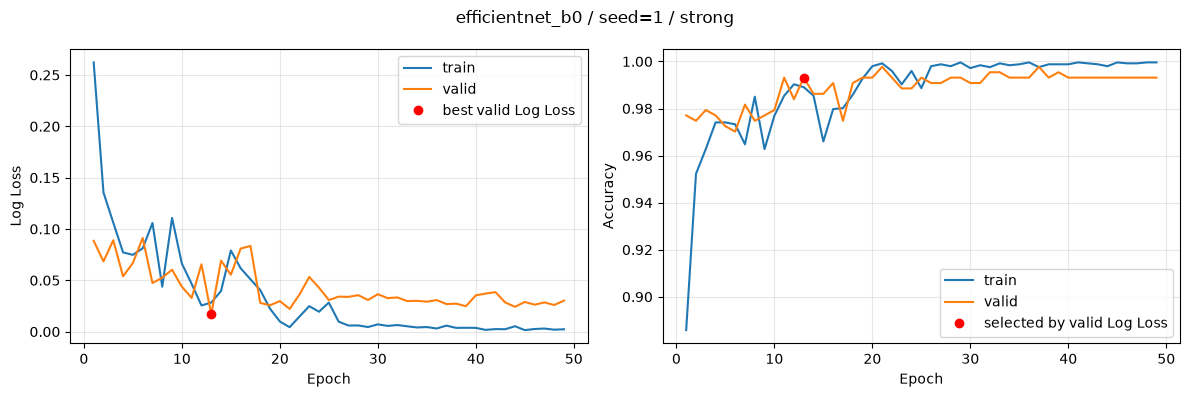


모델: efficientnet_b0 / seed: 2 / 증강: strong
파라미터 수: 4,008,829
Epoch 1/50 | lr 0.001 | train loss 0.2663, acc 0.889 | valid loss 0.0824, acc 0.968
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed2.pt 저장
Epoch 2/50 | lr 0.001 | train loss 0.1470, acc 0.939 | valid loss 0.0700, acc 0.972
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed2.pt 저장
Epoch 3/50 | lr 0.001 | train loss 0.1094, acc 0.959 | valid loss 0.0876, acc 0.966
Epoch 4/50 | lr 0.001 | train loss 0.0978, acc 0.961 | valid loss 0.0470, acc 0.977
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed2.pt 저장
Epoch 5/50 | lr 0.001 | train loss 0.0725, acc 0.972 | valid loss 0.1074, acc 0.975
Epoch 6/50 | lr 0.001 | train loss 0.0775, acc 0.974 | valid loss 0.0580, acc 0.982
Epoch 7/50 | lr 0.001 | train lo

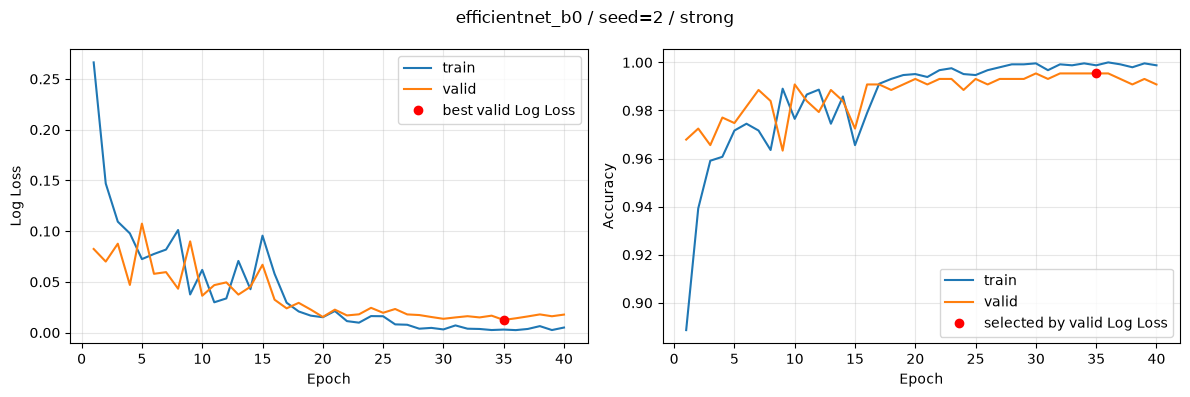


모델: efficientnet_b0 / seed: 3 / 증강: erasing
파라미터 수: 4,008,829
Epoch 1/50 | lr 0.001 | train loss 0.2526, acc 0.891 | valid loss 0.0735, acc 0.977
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed3.pt 저장
Epoch 2/50 | lr 0.001 | train loss 0.1211, acc 0.957 | valid loss 0.0649, acc 0.975
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed3.pt 저장
Epoch 3/50 | lr 0.001 | train loss 0.1107, acc 0.961 | valid loss 0.0512, acc 0.991
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed3.pt 저장
Epoch 4/50 | lr 0.001 | train loss 0.0854, acc 0.968 | valid loss 0.1061, acc 0.959
Epoch 5/50 | lr 0.001 | train loss 0.1176, acc 0.955 | valid loss 0.1603, acc 0.927
Epoch 6/50 | lr 0.001 | train loss 0.0704, acc 0.974 | valid loss 0.0519, acc 0.982
Epoch 7/50 | lr 0.001 | train l

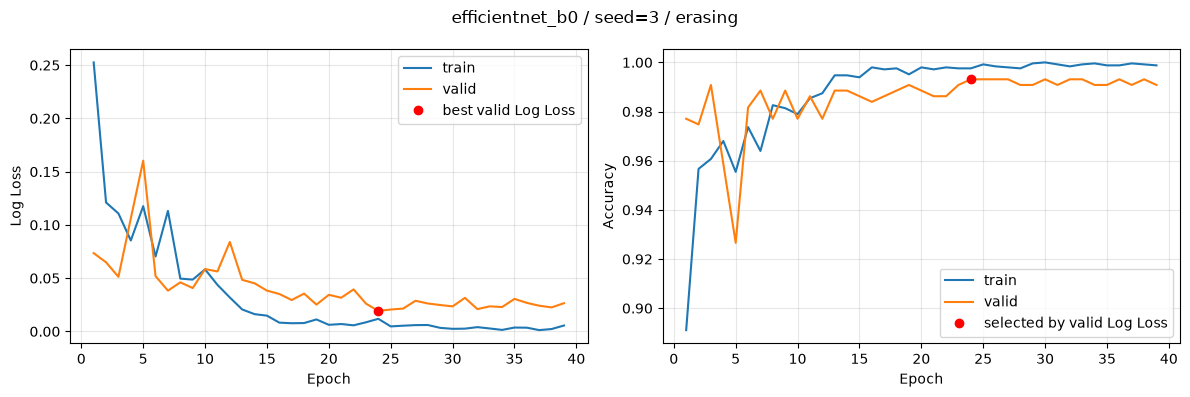


모델: efficientnet_b0 / seed: 4 / 증강: perspective
파라미터 수: 4,008,829
Epoch 1/50 | lr 0.001 | train loss 0.2675, acc 0.893 | valid loss 0.0722, acc 0.977
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed4.pt 저장
Epoch 2/50 | lr 0.001 | train loss 0.1321, acc 0.955 | valid loss 0.1170, acc 0.954
Epoch 3/50 | lr 0.001 | train loss 0.1090, acc 0.961 | valid loss 0.0476, acc 0.982
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed4.pt 저장
Epoch 4/50 | lr 0.001 | train loss 0.0890, acc 0.970 | valid loss 0.1013, acc 0.977
Epoch 5/50 | lr 0.001 | train loss 0.0871, acc 0.972 | valid loss 0.0710, acc 0.977
Epoch 6/50 | lr 0.001 | train loss 0.0764, acc 0.972 | valid loss 0.0408, acc 0.984
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\checkpoints\efficientnet_b0_seed4.pt 저장
Epoch 7/50 | lr 0.001 | tra

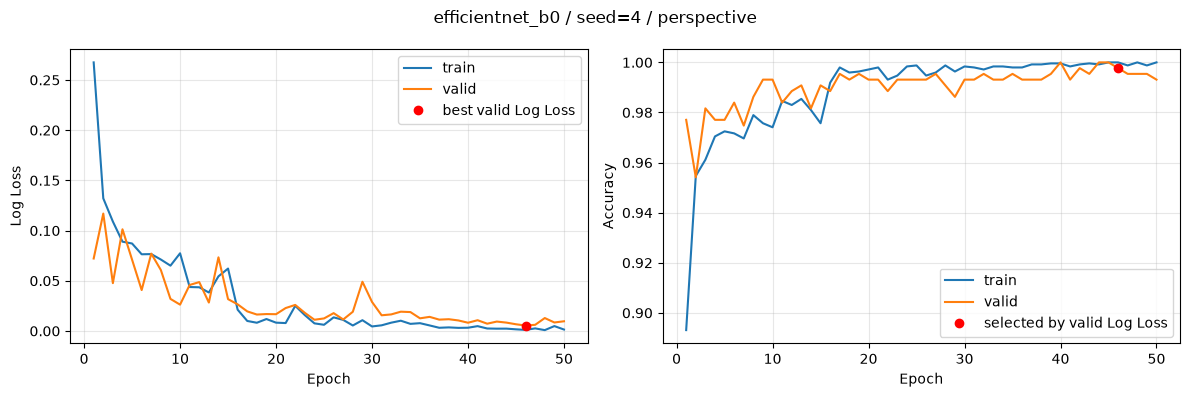

In [15]:
# 실제 실행은 프로젝트 루트에서 수행하고, 저장된 학습 코드를 실험 폴더에 복사합니다.
for filename in ("baseline_test.ipynb", "model.py"):
	shutil.copy2(BASE_DIR / filename, CODE_DIR / filename)

for seed in RUN_SEEDS:
	augmentation = AUGMENTATION_BY_SEED[seed]
	settings = AUGMENTATION_SETTINGS[augmentation]
	full_run_train = datasets.ImageFolder(data_path, train_transforms[augmentation])
	assert full_run_train.samples == full_train.samples, "이미지 순서 또는 라벨이 달라졌습니다."
	run_data_sets = {"train": Subset(full_run_train, train_idx), "valid": data_sets["valid"]}
	print(f"\n{'=' * 60}")
	print(f"모델: efficientnet_b0 / seed: {seed} / 증강: {augmentation}", flush=True)
	seed_everything(seed)

	model = model_module.build_model(pretrained=True).to(device)
	n_params = sum(p.numel() for p in model.parameters())
	assert n_params <= PARAM_LIMIT, f"파라미터 제한 초과: {n_params:,}"
	print(f"파라미터 수: {n_params:,}")

	# 모델 생성에서 소비한 난수와 데이터 로딩 난수를 분리합니다.
	seed_everything(seed)
	dataloaders = {
		"train": DataLoader(run_data_sets["train"], batch_size=params["batch_size"], shuffle=True, num_workers=params["workers"], generator=torch.Generator().manual_seed(seed)),
		"valid": DataLoader(run_data_sets["valid"], batch_size=params["batch_size"], shuffle=False, num_workers=params["workers"], generator=torch.Generator().manual_seed(seed)),
	}
	criterion = nn.BCEWithLogitsLoss()
	optimizer = torch.optim.Adam(model.parameters(), lr=params["learning_rates"][0])
	pt_file_name = CHECKPOINT_DIR / f"efficientnet_b0_seed{seed}.pt"

	if device.type == "cuda":
		torch.cuda.synchronize(device)
	started = time.perf_counter()

	with (EPOCH_DIR / f"efficientnet_b0_seed{seed}.csv").open("w", newline="", encoding="utf-8-sig") as epoch_csv:
		history, best_epoch, best_loss = train_model(model, dataloaders, criterion, optimizer, num_epochs=params["epoch"], epoch_csv=epoch_csv, early_stopping=params["early_stopping"], min_epochs=params["min_epochs"], patience=params["patience"], learning_rates=params["learning_rates"])

	if device.type == "cuda":
		torch.cuda.synchronize(device)
	elapsed = time.perf_counter() - started

	results.append({
		"model": "efficientnet_b0",
		"split_seed": SEED,
		"seed": seed,
		"augmentation": augmentation,
		"selection_metric": "valid_loss",
		"image_size": IMG_SIZE,
		"preprocessing": "crop_then_aspect_resize_pad",
		"erase_p": settings["erase_p"],
		"erase_scale": "(0.02, 0.1)",
		"perspective_p": settings["perspective_p"],
		"distortion_scale": settings["distortion_scale"],
		"scale_min": settings["scale_min"],
		"brightness": settings["brightness"],
		"contrast": settings["contrast"],
		"saturation": settings["saturation"],
		"learning_rates": str(params["learning_rates"]),
		"valid_loss_first12": min(history["valid_loss"][:12]),
		"valid_acc_first12": max(history["valid_acc"][:12]),
		"max_epochs": params["epoch"],
		"epochs_run": len(history["train_loss"]),
		"early_stopping": params["early_stopping"],
		"min_epochs": params["min_epochs"],
		"patience": params["patience"],
		"best_epoch": best_epoch,
		"valid_loss": best_loss,
		"valid_acc": history["valid_acc"][best_epoch - 1],
		"seconds": elapsed,
		"n_params": n_params,
		"checkpoint": str(pt_file_name),
	})

	# 실험 도중 중단돼도 완료된 실행의 지표는 CSV에 남깁니다.
	with (RESULT_DIR / "runs.csv").open("w", newline="", encoding="utf-8-sig") as f:
		writer = csv.DictWriter(f, fieldnames=list(results[0]))
		writer.writeheader()
		writer.writerows(results)

	epochs = range(1, len(history["train_loss"]) + 1)
	fig, axes = plt.subplots(1, 2, figsize=(12, 4))
	axes[0].plot(epochs, history["train_loss"], label="train")
	axes[0].plot(epochs, history["valid_loss"], label="valid")
	axes[0].plot(best_epoch, best_loss, "ro", label="best valid Log Loss")
	axes[0].set_ylabel("Log Loss")
	axes[1].plot(epochs, history["train_acc"], label="train")
	axes[1].plot(epochs, history["valid_acc"], label="valid")
	axes[1].plot(best_epoch, history["valid_acc"][best_epoch - 1], "ro", label="selected by valid Log Loss")
	axes[1].set_ylabel("Accuracy")
	for ax in axes:
		ax.set_xlabel("Epoch")
		ax.legend()
		ax.grid(alpha=0.3)
	fig.suptitle(f"efficientnet_b0 / seed={seed} / {augmentation}")
	fig.tight_layout()
	fig.savefig(GRAPH_DIR / f"efficientnet_b0_seed{seed}.png", dpi=160, bbox_inches="tight")
	plt.show()
	plt.close(fig)
	del optimizer, model, dataloaders


### 전체 통계

각 시드의 최저 검증 Log Loss와 해당 epoch의 ACC를 집계하고 4회 평균과 표본 표준편차를 저장합니다.


In [16]:
assert len(results) == len(RUN_SEEDS), "모든 시드의 실행을 완료해야 합니다."

losses = np.array([row["valid_loss"] for row in results])
accuracies = np.array([row["valid_acc"] for row in results])
seconds = np.array([row["seconds"] for row in results])
summary = {
	"model": "efficientnet_b0",
	"split_seed": SEED,
	"runs": len(results),
	"loss_mean": float(losses.mean()),
	"loss_std": float(losses.std(ddof=1)),
	"accuracy_mean": float(accuracies.mean()),
	"accuracy_std": float(accuracies.std(ddof=1)),
	"seconds_mean": float(seconds.mean()),
	"seconds_std": float(seconds.std(ddof=1)),
	"n_params": results[0]["n_params"],
}
with (RESULT_DIR / "summary.csv").open("w", newline="", encoding="utf-8-sig") as f:
	writer = csv.DictWriter(f, fieldnames=list(summary))
	writer.writeheader()
	writer.writerow(summary)

print(f"검증 Log Loss: {summary['loss_mean']:.4f} ± {summary['loss_std']:.4f}")
print(f"검증 정확도: {summary['accuracy_mean']:.2%} ± {summary['accuracy_std']:.2%}")
print(f"전체 학습 시간: {seconds.sum() / 60:.1f}분")
print("실행별 결과:", RESULT_DIR / "runs.csv")
print("전체 통계:", RESULT_DIR / "summary.csv")



검증 Log Loss: 0.0135 ± 0.0061
검증 정확도: 99.48% ± 0.22%
전체 학습 시간: 29.4분
실행별 결과: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\runs.csv
전체 통계: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\summary.csv


### 두 temperature 규칙의 앙상블 검증

전원 일치이면 확률 평균, 불일치이면 가운데 두 확률 평균을 사용합니다.
T0.3 규칙은 일치 T=0.3·불일치 T=0.7, T0.5 규칙은 모두 T=0.5입니다.
같은 모델의 예측에서 두 규칙을 동시에 계산하고 전체·의견별 검증 결과를 저장합니다.


In [17]:
assert [row["seed"] for row in results] == list(RUN_SEEDS)
ensemble_weights_path = RESULT_DIR / "ensemble.pt"
checkpoint = {
	"seeds": list(RUN_SEEDS),
	"split_seed": SEED,
	"temperature_rules": list(model_module.TEMPERATURE_RULES),
	"augmentations": [AUGMENTATION_BY_SEED[seed] for seed in RUN_SEEDS],
	"image_size": IMG_SIZE,
	"preprocessing": "aspect_resize_pad",
	"temperatures": [model_module.CONSENSUS_TEMPERATURE, model_module.DISAGREEMENT_TEMPERATURE],
	"state_dicts": [torch.load(row["checkpoint"], map_location="cpu", weights_only=True) for row in results],
}
ensemble = model_module.EfficientNetEnsemble(checkpoint["state_dicts"]).to(device)
ensemble.eval()
ensemble_params = sum(p.numel() for p in ensemble.parameters())
assert ensemble_params <= PARAM_LIMIT, f"앙상블 파라미터 제한 초과: {ensemble_params:,}"
torch.save(checkpoint, ensemble_weights_path)

valid_loader = DataLoader(data_sets["valid"], batch_size=params["batch_size"], shuffle=False, num_workers=0)
validation_probabilities, validation_targets = [], []
with torch.inference_mode():
	for inputs, targets in valid_loader:
		validation_probabilities.append(ensemble.member_probabilities(inputs.to(device)).cpu())
		validation_targets.append(targets)
member_probs = torch.cat(validation_probabilities)
targets = torch.cat(validation_targets).float()
mean_probs = member_probs.mean(dim=1, keepdim=True)
middle_probs = member_probs.sort(dim=1).values[:, 1:3].mean(dim=1, keepdim=True)
ensemble_probs_by_rule = {rule: model_module.combine_probabilities(member_probs, rule) for rule in model_module.TEMPERATURE_RULES}
all_probs = torch.cat((member_probs, mean_probs, middle_probs, *ensemble_probs_by_rule.values()), dim=1)
names = [f"seed{seed}" for seed in RUN_SEEDS] + ["mean_T1", "middle_T1"] + list(model_module.TEMPERATURE_RULES)
metrics = []
for index, name in enumerate(names):
	probs = all_probs[:, index]
	accuracy = ((probs >= 0.5) == targets.bool()).float().mean().item()
	loss = torch.nn.functional.binary_cross_entropy(probs.clamp(1e-6, 1 - 1e-6), targets).item()
	metrics.append({"model": name, "samples": len(targets), "valid_acc": accuracy, "valid_loss": loss})
	print(f"{name}: ACC {accuracy:.2%} / Log Loss {loss:.5f}")
for filename, rows in (("ensemble_metrics.csv", metrics), ("comparison.csv", metrics[-4:])):
	with (RESULT_DIR / filename).open("w", newline="", encoding="utf-8-sig") as f:
		writer = csv.DictWriter(f, fieldnames=list(rows[0]))
		writer.writeheader()
		writer.writerows(rows)

positive_votes = (member_probs >= 0.5).sum(dim=1)
unanimous = (positive_votes == 0) | (positive_votes == 4)
agreement_metrics = []
for rule, ensemble_probs in ensemble_probs_by_rule.items():
	for name, mask in (
		("4:0", unanimous),
		("3:1", (positive_votes == 1) | (positive_votes == 3)),
		("2:2", positive_votes == 2),
	):
		count = int(mask.sum())
		row = {"rule": rule, "agreement": name, "samples": count, "valid_acc": None, "valid_loss": None}
		if count > 0:
			probs = ensemble_probs.squeeze(1)[mask]
			labels = targets[mask]
			row["valid_acc"] = ((probs >= 0.5) == labels.bool()).float().mean().item()
			row["valid_loss"] = torch.nn.functional.binary_cross_entropy(probs.clamp(1e-6, 1 - 1e-6), labels).item()
		agreement_metrics.append(row)
with (RESULT_DIR / "agreement_metrics.csv").open("w", newline="", encoding="utf-8-sig") as f:
	writer = csv.DictWriter(f, fieldnames=list(agreement_metrics[0]))
	writer.writeheader()
	writer.writerows(agreement_metrics)

with (RESULT_DIR / "validation_predictions.csv").open("w", newline="", encoding="utf-8-sig") as f:
	writer = csv.writer(f)
	writer.writerow(["id", "label", "positive_votes", "T0.3_temperature", "T0.5_temperature"] + [f"{name}_prob" for name in names])
	for position, sample_index in enumerate(valid_idx):
		image_id = Path(full_valid.samples[sample_index][0]).stem
		temperature = model_module.CONSENSUS_TEMPERATURE if bool(unanimous[position]) else model_module.DISAGREEMENT_TEMPERATURE
		writer.writerow([image_id, int(targets[position]), int(positive_votes[position]), temperature, 0.5] + all_probs[position].tolist())
print(f"앙상블 파라미터: {ensemble_params:,}")
print("앙상블 가중치:", ensemble_weights_path)


seed1: ACC 99.31% / Log Loss 0.01703
seed2: ACC 99.54% / Log Loss 0.01251
seed3: ACC 99.31% / Log Loss 0.01922
seed4: ACC 99.77% / Log Loss 0.00543
mean_T1: ACC 99.31% / Log Loss 0.01126
middle_T1: ACC 99.54% / Log Loss 0.00896
T0.3: ACC 99.54% / Log Loss 0.01408
T0.5: ACC 99.54% / Log Loss 0.01045
앙상블 파라미터: 16,035,316
앙상블 가중치: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\ensemble.pt


## 테스트 추론 — 두 제출 CSV 동시 생성

아래 추론 셀 한 번으로 개별 모델 CSV와 두 temperature 규칙의 CSV를 생성합니다. 기존 CSV에 temperature를 다시 적용하지 않습니다.


In [23]:
class TestImageDataset(Dataset):
    def __init__(self, files, transform):
        self.files = files
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        file = self.files[index]
        img = Image.open(file).convert('RGB')
        return self.transform(img), os.path.basename(file)


import glob
test_files = sorted(glob.glob('./test/*'))
print('테스트 이미지 수:', len(test_files))

test_loader = DataLoader(
    TestImageDataset(test_files, valid_transform),
    batch_size=params['batch_size'], shuffle=False)

테스트 이미지 수: 500


In [24]:
submission_names = [f"seed{seed}" for seed in RUN_SEEDS] + list(model_module.TEMPERATURE_RULES) + ["T0.3_TTA"]
submission_rows = {name: ["id,prob"] for name in submission_names}
ensemble.eval()
with torch.inference_mode():
	for inputs, filenames in test_loader:
		inputs = inputs.to(device)
		member_probs = ensemble.member_probabilities(inputs).cpu()
		flipped_member_probs = ensemble.member_probabilities(inputs.flip(dims=[3])).cpu()
		tta_member_probs = (member_probs + flipped_member_probs) / 2
		ensemble_probs = [model_module.combine_probabilities(member_probs, rule) for rule in model_module.TEMPERATURE_RULES]
		tta_probs = model_module.combine_probabilities(tta_member_probs, "T0.3")
		all_probs = torch.cat((member_probs, *ensemble_probs, tta_probs), dim=1)
		for filename, probabilities in zip(filenames, all_probs):
			image_id = Path(filename).stem
			for name, probability in zip(submission_names, probabilities):
				submission_rows[name].append(f"{image_id},{probability.item():.6f}")
submission_paths = {}
for name, rows in submission_rows.items():
	path = RESULT_DIR / f"submission_{SEED}_{name}.csv"
	path.write_text("\n".join(rows) + "\n", encoding="utf-8")
	submission_paths[name] = path
	print("제출 CSV:", path)


제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\submission_1_seed1.csv
제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\submission_1_seed2.csv
제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\submission_1_seed3.csv
제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\submission_1_seed4.csv
제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\submission_1_T0.3.csv
제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\submission_1_T0.5.csv
제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\submission_1_T0.3_TTA.csv


## 제출 패키지

model.py·predict.py·baseline_test.ipynb·네 모델을 담은 model.pt를 ZIP에 보관합니다.
기존 규칙은 아래 명령의 기본값 T0.3이며, T0.5 제출을 재현하려면 해당 인수를 지정합니다.

```shell
python predict.py --input <테스트 폴더> --output pred.csv --temperature-rule T0.3
python predict.py --input <테스트 폴더> --output pred.csv --temperature-rule T0.5
```


In [26]:
%%writefile predict.py
import argparse
import glob
import os

import torch
from PIL import Image
from model import IMG_SIZE, TEMPERATURE_RULES, EfficientNetEnsemble, build_valid_transform, combine_probabilities

PARAM_LIMIT = 20_000_000


def load_images(input_dir):
	exts = (".jpg", ".jpeg", ".png")
	return sorted(f for f in glob.glob(os.path.join(input_dir, "*")) if f.lower().endswith(exts))


def main():
	parser = argparse.ArgumentParser()
	parser.add_argument("--input", required=True, help="테스트 이미지 폴더")
	parser.add_argument("--output", required=True, help="출력 CSV 경로")
	parser.add_argument("--weights", default="model.pt", help="앙상블 가중치 파일")
	parser.add_argument("--temperature-rule", choices=TEMPERATURE_RULES, default="T0.3", help="T0.3은 기존 조건부 규칙, T0.5는 전체 0.5 규칙")
	parser.add_argument("--tta", action="store_true", help="원본·좌우 반전 확률을 평균한 뒤 조건부 T0.3 적용")
	args = parser.parse_args()
	if args.tta and (args.temperature_rule != "T0.3"):
		parser.error("--tta는 --temperature-rule T0.3과 함께 사용하세요.")

	device = torch.device("cpu")
	weights_path = os.path.join(os.path.dirname(os.path.abspath(__file__)), args.weights)
	checkpoint = torch.load(weights_path, map_location="cpu", weights_only=True)
	assert checkpoint["image_size"] == IMG_SIZE, "가중치의 입력 크기를 확인하세요."
	model = EfficientNetEnsemble(checkpoint["state_dicts"]).to(device)
	model.eval()

	n_params = sum(p.numel() for p in model.parameters())
	print(f"앙상블 파라미터 수: {n_params:,} (제한 {PARAM_LIMIT:,})")
	assert n_params <= PARAM_LIMIT, "파라미터 20M 초과!"

	transform = build_valid_transform()
	files = load_images(args.input)
	assert len(files) > 0, f"{args.input}에서 이미지를 찾지 못했습니다."

	rows = ["id,prob"]
	with torch.inference_mode():
		for i in range(0, len(files), 32):
			batch_files = files[i:i + 32]
			images = []
			for file in batch_files:
				with Image.open(file) as image:
					images.append(transform(image.convert("RGB")))
			inputs = torch.stack(images).to(device)
			if args.tta:
				member_probs = model.member_probabilities(inputs)
				flipped_member_probs = model.member_probabilities(inputs.flip(dims=[3]))
				probs = combine_probabilities((member_probs + flipped_member_probs) / 2, "T0.3").squeeze(1)
			else:
				probs = model(inputs, temperature_rule=args.temperature_rule).squeeze(1)
			for file, prob in zip(batch_files, probs):
				rows.append(f"{os.path.splitext(os.path.basename(file))[0]},{prob.item():.6f}")

	with open(args.output, "w", encoding="utf-8") as f:
		f.write("\n".join(rows) + "\n")
	print(f"{args.output} 저장 완료 ({len(files)}장)")


if __name__ == "__main__":
	main()


Overwriting predict.py


In [27]:
package_dir = RESULT_DIR / "package"
assert package_dir.resolve().parent == RESULT_DIR.resolve()
if package_dir.exists():
	shutil.rmtree(package_dir)
package_dir.mkdir()
shutil.copy2(BASE_DIR / "predict.py", CODE_DIR / "predict.py")
for filename in ("model.py", "predict.py", "baseline_test.ipynb"):
	shutil.copy2(CODE_DIR / filename, package_dir / filename)
shutil.copyfile(ensemble_weights_path, package_dir / "model.pt")
zip_path = shutil.make_archive(str(RESULT_DIR / "submission_package"), "zip", package_dir)
assert Path(zip_path).stat().st_size <= 200_000_000, "ZIP 200MB 초과"
print("앙상블 패키지 생성:", zip_path)


앙상블 패키지 생성: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_1\submission_package.zip


### 패키지 자가 검증 (제출 전 필수!)

운영진 검증과 같은 방식으로, 패키지 폴더 안에서 `predict.py`를 CPU로 실행해 봅니다. 여기서 에러가 나면 검증도 실패합니다. Colab 런타임을 CPU로 두고 실행하면 10분 기준도 함께 확인할 수 있습니다.

In [ ]:
import sys
subprocess_env = os.environ.copy()
subprocess_env["PYTHONIOENCODING"] = "utf-8"
check_cases = [(rule, rule, False) for rule in model_module.TEMPERATURE_RULES] + [("T0.3_TTA", "T0.3", True)]
for name, rule, use_tta in check_cases:
	package_check_path = RESULT_DIR / f"package_check_{SEED}_{name}.csv"
	command = [sys.executable, str(package_dir / "predict.py"), "--input", str(BASE_DIR / "test"), "--output", str(package_check_path), "--temperature-rule", rule]
	if use_tta:
		command.append("--tta")
	started = time.perf_counter()
	result = subprocess.run(
		command,
		capture_output=True, text=True, encoding="utf-8", check=True, env=subprocess_env,
	)
	elapsed = time.perf_counter() - started
	print(result.stdout)
	print(result.stderr)
	print(f"{name} CPU 추론 시간: {elapsed:.1f}초")
	assert elapsed <= 600, "CPU 추론 10분 초과"

	with submission_paths[name].open(newline="", encoding="utf-8") as f:
		nb_probs = {row["id"]: float(row["prob"]) for row in csv.DictReader(f)}
	with package_check_path.open(newline="", encoding="utf-8") as f:
		pkg_probs = {row["id"]: float(row["prob"]) for row in csv.DictReader(f)}
	assert nb_probs.keys() == pkg_probs.keys(), "파일 목록이 다릅니다."
	max_diff = max(abs(nb_probs[key] - pkg_probs[key]) for key in nb_probs)
	print(f"{name} 노트북 vs 패키지 확률 최대 차이: {max_diff:.2e}")
	assert max_diff < 1e-3, "전처리·가중치·앙상블 방식을 확인하세요."
print("두 temperature 규칙과 TTA 패키지 자가 검증 통과")


## 제출 전 체크리스트

- [ ] 세 `submission_{SEED}_T*.csv`가 `id,prob` 형식이고 테스트 500장 전부를 포함하는가?
- [ ] 파라미터 카운터 셀에서 **20M 이하**를 확인했는가? (앙상블·사전학습 백본 합산)
- [ ] 패키지 자가 검증 셀이 에러 없이 통과했는가? (Colab CPU 에서 500장 10분 이내)
- [ ] TTA 제출은 `--temperature-rule T0.3 --tta`로 재현되는가?
- [ ] `predict.py`가 네트워크 없이 동작하는가? (다운로드 코드 금지, 가중치는 패키지에 동봉)
- [ ] 테스트 이미지를 학습에 사용하지 않았는가? (pseudo-labeling 포함 금지)
- [ ] 외부 이미지를 학습에 사용하지 않았는가?

## 개선 아이디어

- 채널 수·블록 수 조정, 학습률 스케줄러(CosineAnnealing 등) 추가
- 20M 이내의 사전학습 백본(MobileNetV3, EfficientNet-B0 등) fine-tuning — 가중치를 패키지에 포함할 것
- 증강 다양화: 밝기·색감·회전·노이즈 — 처음 보는 촬영 조건에 대한 일반화
- 검증 전략 개선: k-fold 교차검증으로 점수 추정의 신뢰도 높이기
- 과확신 완화: label smoothing, 확률 클리핑, 온도 조절(temperature scaling)
